# Consumer Complaint Classification
End-to-end NLP pipeline: SimpleRNN vs LSTM vs GRU (from scratch) vs a fine-tuned HuggingFace transformer.

**Run on Google Colab with a GPU** (Runtime > Change runtime type > T4 GPU).

Pipeline: load data > explore > preprocess > class balance > tokenize + pad > embedding > train 4 models > evaluate > compare > predict > save artifacts for Gradio.

## 1. Setup

In [3]:
!pip install -q kagglehub transformers accelerate scikit-learn nltk

In [4]:
import os, re, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print('TensorFlow', tf.__version__, '| GPUs:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Configuration
Change these values to trade speed for accuracy.

In [5]:
TOP_N_CLASSES   = 8       # keep the N most frequent complaint categories
MAX_PER_CLASS   = 6000    # cap per class (controls imbalance + training time)
MAX_VOCAB       = 20000   # tokenizer vocabulary size
MAX_LEN         = 200     # padded sequence length for RNN models
EMBED_DIM       = 128
BATCH_SIZE      = 128
EPOCHS          = 15
USE_LEMMATIZER  = True    # lemmatization (optional step)

TRANSFORMER_NAME   = 'distilbert-base-uncased'
TRANSFORMER_MAXLEN = 256
TRANSFORMER_EPOCHS = 3
TRANSFORMER_TRAIN_CAP = 20000   # max training rows for the transformer (speed)

ARTIFACTS_DIR = 'artifacts'
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

## 3. Import and explore the dataset

In [6]:
import kagglehub
path = kagglehub.dataset_download('shashwatwork/consume-complaints-dataset-fo-nlp')
print('Downloaded to:', path)
csv_files = [os.path.join(r, f) for r, _, fs in os.walk(path) for f in fs if f.endswith('.csv')]
print(csv_files)

Using Colab cache for faster access to the 'consume-complaints-dataset-fo-nlp' dataset.
Downloaded to: /kaggle/input/consume-complaints-dataset-fo-nlp
['/kaggle/input/consume-complaints-dataset-fo-nlp/complaints_processed.csv']


In [7]:
csv_path = csv_files[0]
header = pd.read_csv(csv_path, nrows=0).columns.tolist()
print('Columns:', header)

def find_col(options):
    for o in options:
        for c in header:
            if c.lower().strip() == o:
                return c
    return None

TEXT_COL  = find_col(['consumer complaint narrative', 'consumer_complaint_narrative', 'narrative', 'complaint'])
LABEL_COL = find_col(['product', 'category', 'label'])
print('Text column :', TEXT_COL)
print('Label column:', LABEL_COL)

df = pd.read_csv(csv_path, usecols=[TEXT_COL, LABEL_COL])[[TEXT_COL, LABEL_COL]]  # force (text, label) order
df.columns = ['text', 'label']
print('Raw shape:', df.shape)
df.head()

Columns: ['Unnamed: 0', 'product', 'narrative']
Text column : narrative
Label column: product
Raw shape: (162421, 2)


,text,label
0,purchase order day shipping amount receive pro...,credit_card
1,forwarded message date tue subject please inve...,credit_card
2,forwarded message cc sent friday pdt subject f...,retail_banking
3,payment history missing credit report speciali...,credit_reporting
4,payment history missing credit report made mis...,credit_reporting


In [8]:
print(df.isna().sum())
df = df.dropna(subset=['text', 'label']).drop_duplicates(subset='text').reset_index(drop=True)
print('After dropping missing/duplicates:', df.shape)
print('\nNumber of categories:', df['label'].nunique())
df['label'].value_counts()

text     10
label     0
dtype: int64
After dropping missing/duplicates: (124472, 2)

Number of categories: 5


,count
label,
credit_reporting,56240
debt_collection,21057
mortgages_and_loans,18723
credit_card,14983
retail_banking,13469


## 4. Class distribution and imbalance handling

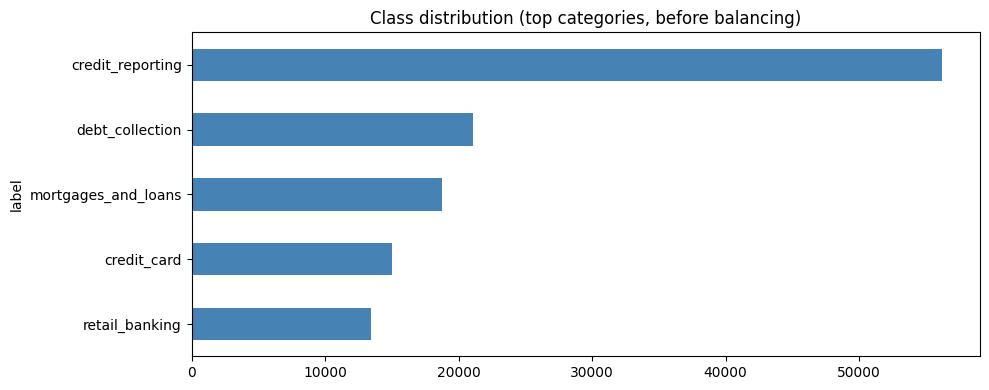

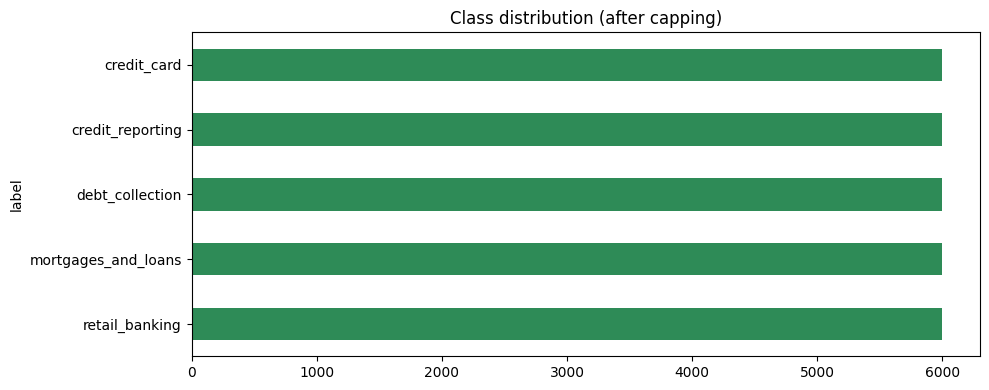

(30000, 2)


In [9]:
top = df['label'].value_counts().head(TOP_N_CLASSES).index
df = df[df['label'].isin(top)].reset_index(drop=True)

plt.figure(figsize=(10, 4))
df['label'].value_counts().plot(kind='barh', color='steelblue')
plt.title('Class distribution (top categories, before balancing)')
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

# Cap the large classes (undersampling); remaining imbalance is handled with class weights during training
df = (df.groupby('label', group_keys=False)
        .apply(lambda g: g.sample(min(len(g), MAX_PER_CLASS), random_state=SEED))
        .reset_index(drop=True))

plt.figure(figsize=(10, 4))
df['label'].value_counts().plot(kind='barh', color='seagreen')
plt.title('Class distribution (after capping)')
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()
print(df.shape)

## 5. Text preprocessing
Lowercasing, removing punctuation / numbers / special characters, removing stop words, lemmatization (optional).

In [10]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'x{2,}', ' ', text)          # redaction masks such as XXXX
    text = re.sub(r'[^a-z\s]', ' ', text)        # punctuation, numbers, special characters
    tokens = [w for w in text.split() if w not in stop_words and len(w) > 1]
    if USE_LEMMATIZER:
        tokens = [lemmatizer.lemmatize(w) for w in tokens]
    return ' '.join(tokens)

def light_clean(text):
    # used for the transformer: keep stop words and word order intact
    text = str(text).lower()
    text = re.sub(r'x{2,}', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

df['clean_text'] = df['text'].apply(clean_text)
df['raw_text']   = df['text'].apply(light_clean)
df = df[df['clean_text'].str.len() > 0].reset_index(drop=True)

print(df[['text', 'clean_text']].head(3).to_string())
df['n_words'] = df['clean_text'].str.split().str.len()
df['n_words'].describe()

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             text                                                                                       

,n_words
count,30000.000000
mean,93.323333
std,110.582571
min,1.000000
25%,34.000000
50%,64.000000
75%,113.000000
max,2325.000000


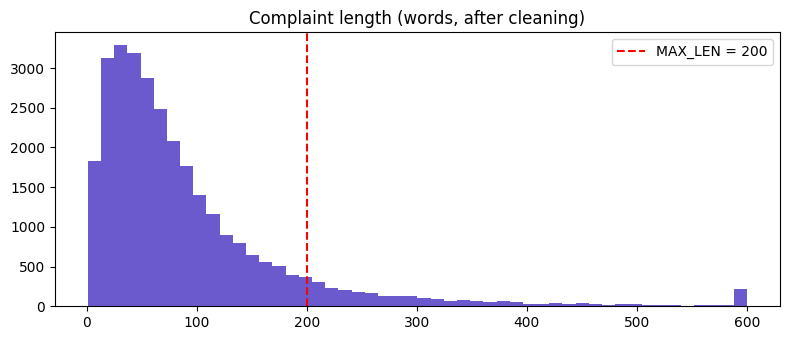

In [11]:
plt.figure(figsize=(8, 3.5))
plt.hist(df['n_words'].clip(upper=600), bins=50, color='slateblue')
plt.axvline(MAX_LEN, color='red', linestyle='--', label=f'MAX_LEN = {MAX_LEN}')
plt.title('Complaint length (words, after cleaning)'); plt.legend(); plt.tight_layout(); plt.show()

## 6. Encode labels and split the data

In [12]:
classes = sorted(df['label'].unique())
label2id = {c: i for i, c in enumerate(classes)}
id2label = {i: c for c, i in label2id.items()}
df['y'] = df['label'].map(label2id)
NUM_CLASSES = len(classes)
print(label2id)

train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df['y'], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.5, stratify=temp_df['y'], random_state=SEED)
print(len(train_df), len(val_df), len(test_df))

cw = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=train_df['y'])
class_weights = dict(enumerate(cw))
print('Class weights:', {id2label[k]: round(v, 2) for k, v in class_weights.items()})

{'credit_card': 0, 'credit_reporting': 1, 'debt_collection': 2, 'mortgages_and_loans': 3, 'retail_banking': 4}
24000 3000 3000
Class weights: {'credit_card': np.float64(1.0), 'credit_reporting': np.float64(1.0), 'debt_collection': np.float64(1.0), 'mortgages_and_loans': np.float64(1.0), 'retail_banking': np.float64(1.0)}


## 7. Tokenization and padding

In [13]:
class SimpleTokenizer:
    PAD, OOV = 0, 1
    def __init__(self, max_vocab=20000):
        self.max_vocab = max_vocab
        self.word_index = {}
    def fit(self, texts):
        counts = Counter(w for t in texts for w in t.split())
        for i, (w, _) in enumerate(counts.most_common(self.max_vocab - 2), start=2):
            self.word_index[w] = i
        return self
    def texts_to_sequences(self, texts):
        return [[self.word_index.get(w, self.OOV) for w in t.split()] for t in texts]
    def save(self, path):
        json.dump({'max_vocab': self.max_vocab, 'word_index': self.word_index}, open(path, 'w'))
    @classmethod
    def load(cls, path):
        d = json.load(open(path)); tok = cls(d['max_vocab']); tok.word_index = d['word_index']; return tok

def pad_sequences(seqs, maxlen):
    out = np.zeros((len(seqs), maxlen), dtype='int32')   # post-padding / post-truncating
    for i, s in enumerate(seqs):
        s = s[:maxlen]
        out[i, :len(s)] = s
    return out

tokenizer = SimpleTokenizer(MAX_VOCAB).fit(train_df['clean_text'])
def encode(texts): return pad_sequences(tokenizer.texts_to_sequences(texts), MAX_LEN)

X_train, X_val, X_test = encode(train_df['clean_text']), encode(val_df['clean_text']), encode(test_df['clean_text'])
y_train, y_val, y_test = train_df['y'].values, val_df['y'].values, test_df['y'].values
VOCAB_SIZE = min(MAX_VOCAB, len(tokenizer.word_index) + 2)
print('Vocab size:', VOCAB_SIZE, '| X_train:', X_train.shape)

Vocab size: 20000 | X_train: (24000, 200)


## 8. Models with an Embedding layer: SimpleRNN, LSTM, GRU

In [14]:
def build_model(rnn_type):
    rnn = {'SimpleRNN': layers.SimpleRNN, 'LSTM': layers.LSTM, 'GRU': layers.GRU}[rnn_type]
    model = models.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True),
        rnn(128),
        layers.Dropout(0.4),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax'),
    ], name=rnn_type)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

build_model('LSTM').summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,700,165 (10.30 MB)

 Trainable params: 2,700,165 (10.30 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
histories, keras_models = {}, {}

for name in ['SimpleRNN', 'LSTM', 'GRU']:
    print(f'\n===== Training {name} =====')
    model = build_model(name)
    cb = [callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
          callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1)]
    histories[name] = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                                epochs=EPOCHS, batch_size=BATCH_SIZE,
                                class_weight=class_weights, callbacks=cb, verbose=2)
    keras_models[name] = model


===== Training SimpleRNN =====
Epoch 1/15
188/188 - 18s - 96ms/step - accuracy: 0.4374 - loss: 1.2598 - val_accuracy: 0.5023 - val_loss: 1.1068 - learning_rate: 0.0010
Epoch 2/15
188/188 - 4s - 22ms/step - accuracy: 0.6658 - loss: 0.8283 - val_accuracy: 0.7333 - val_loss: 0.7454 - learning_rate: 0.0010
Epoch 3/15
188/188 - 4s - 22ms/step - accuracy: 0.7850 - loss: 0.6235 - val_accuracy: 0.7400 - val_loss: 0.7689 - learning_rate: 0.0010
Epoch 4/15
188/188 - 4s - 22ms/step - accuracy: 0.8486 - loss: 0.4743 - val_accuracy: 0.7560 - val_loss: 0.7520 - learning_rate: 5.0000e-04
Epoch 5/15
188/188 - 4s - 22ms/step - accuracy: 0.8976 - loss: 0.3255 - val_accuracy: 0.7760 - val_loss: 0.7134 - learning_rate: 2.5000e-04
Epoch 6/15
188/188 - 4s - 22ms/step - accuracy: 0.9193 - loss: 0.2659 - val_accuracy: 0.7713 - val_loss: 0.7743 - learning_rate: 2.5000e-04
Epoch 7/15
188/188 - 4s - 22ms/step - accuracy: 0.9400 - loss: 0.2023 - val_accuracy: 0.7793 - val_loss: 0.7737 - learning_rate: 1.2500e-04

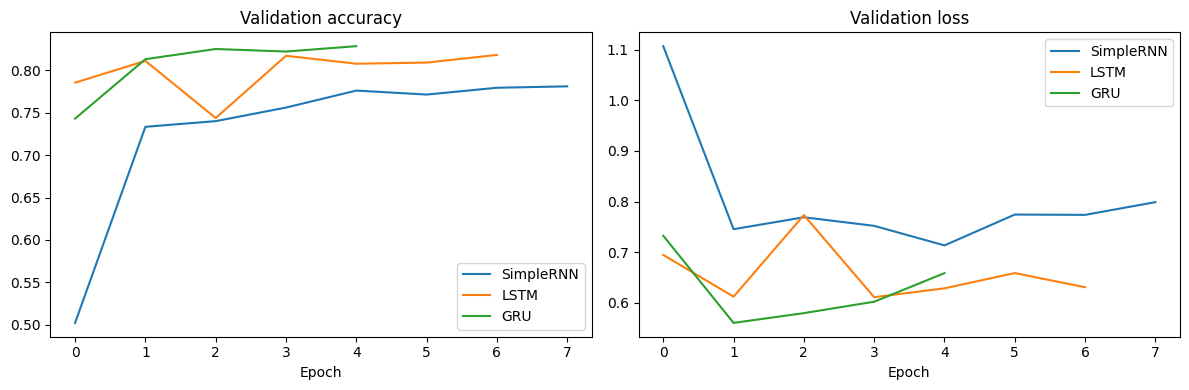

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histories.items():
    ax[0].plot(h.history['val_accuracy'], label=name)
    ax[1].plot(h.history['val_loss'], label=name)
ax[0].set_title('Validation accuracy'); ax[1].set_title('Validation loss')
for a in ax: a.set_xlabel('Epoch'); a.legend()
plt.tight_layout(); plt.show()

## 9. Evaluation helpers

===== SimpleRNN =====
                     precision    recall  f1-score   support

        credit_card       0.76      0.74      0.75       600
   credit_reporting       0.76      0.78      0.77       600
    debt_collection       0.82      0.74      0.78       600
mortgages_and_loans       0.81      0.85      0.83       600
     retail_banking       0.80      0.83      0.81       600

           accuracy                           0.79      3000
          macro avg       0.79      0.79      0.79      3000
       weighted avg       0.79      0.79      0.79      3000



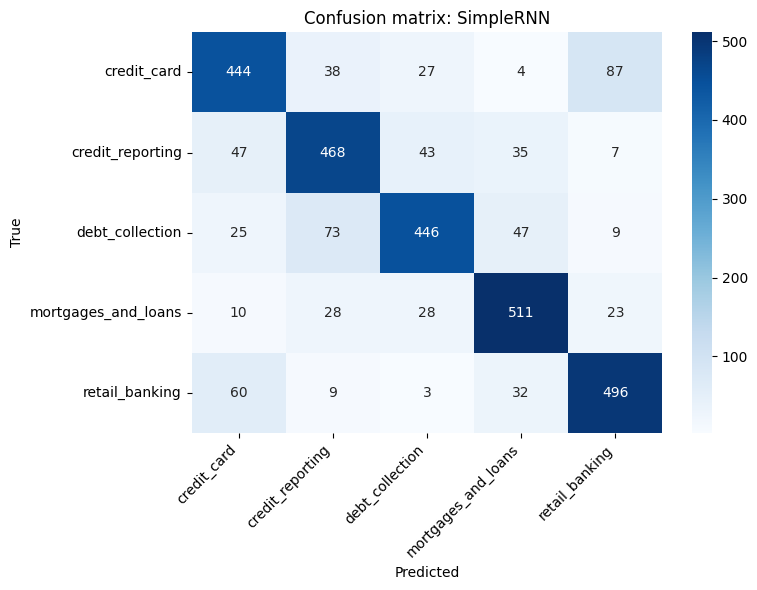

===== LSTM =====
                     precision    recall  f1-score   support

        credit_card       0.81      0.78      0.80       600
   credit_reporting       0.79      0.76      0.77       600
    debt_collection       0.82      0.80      0.81       600
mortgages_and_loans       0.82      0.85      0.84       600
     retail_banking       0.81      0.88      0.85       600

           accuracy                           0.81      3000
          macro avg       0.81      0.81      0.81      3000
       weighted avg       0.81      0.81      0.81      3000



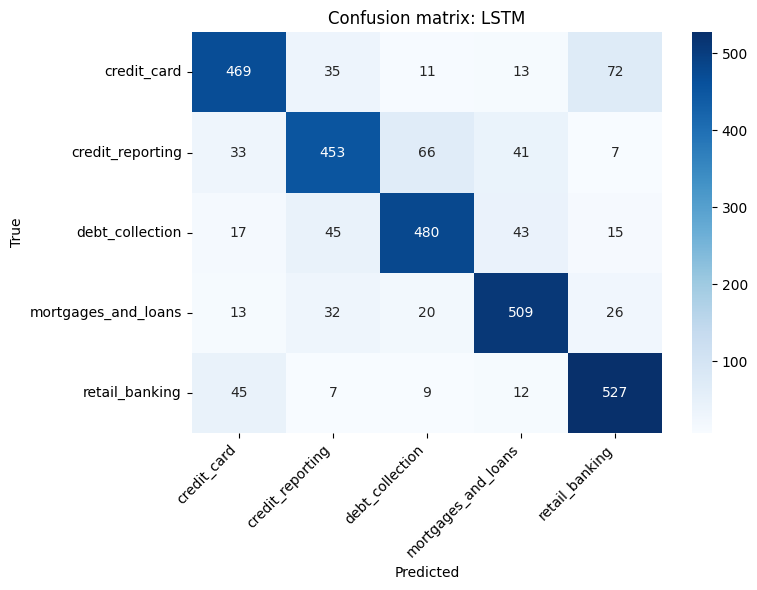

===== GRU =====
                     precision    recall  f1-score   support

        credit_card       0.73      0.85      0.79       600
   credit_reporting       0.80      0.78      0.79       600
    debt_collection       0.84      0.79      0.82       600
mortgages_and_loans       0.89      0.78      0.83       600
     retail_banking       0.85      0.87      0.86       600

           accuracy                           0.82      3000
          macro avg       0.82      0.82      0.82      3000
       weighted avg       0.82      0.82      0.82      3000



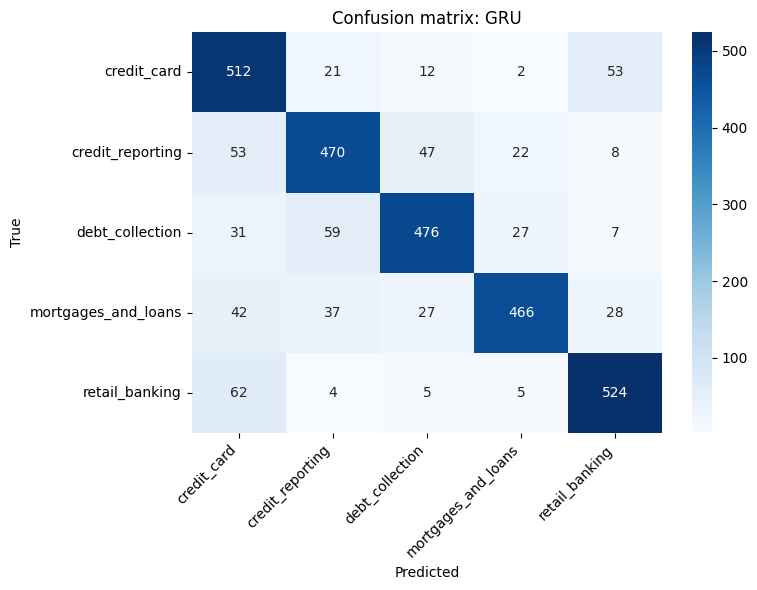

In [17]:
results, all_preds = {}, {}

def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
    results[name] = {'Accuracy': acc, 'Precision': p, 'Recall': r, 'F1-score': f1}
    all_preds[name] = y_pred
    print(f'===== {name} =====')
    print(classification_report(y_true, y_pred, target_names=classes, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.title(f'Confusion matrix: {name}'); plt.xlabel('Predicted'); plt.ylabel('True')
    plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

for name, model in keras_models.items():
    y_pred = model.predict(X_test, batch_size=256, verbose=0).argmax(axis=1)
    evaluate(name, y_test, y_pred)

## 10. Fine-tuned transformer (HuggingFace)

In [18]:
import torch
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, EarlyStoppingCallback)

hf_train = train_df.sample(min(len(train_df), TRANSFORMER_TRAIN_CAP), random_state=SEED)
hf_tok = AutoTokenizer.from_pretrained(TRANSFORMER_NAME)

class ComplaintDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels):
        self.enc = hf_tok(list(texts), truncation=True, max_length=TRANSFORMER_MAXLEN)
        self.labels = list(labels)
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item['labels'] = int(self.labels[i])
        return item

ds_train = ComplaintDataset(hf_train['raw_text'], hf_train['y'])
ds_val   = ComplaintDataset(val_df['raw_text'], val_df['y'])
ds_test  = ComplaintDataset(test_df['raw_text'], test_df['y'])

hf_model = AutoModelForSequenceClassification.from_pretrained(
    TRANSFORMER_NAME, num_labels=NUM_CLASSES, id2label=id2label, label2id=label2id)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average='weighted', zero_division=0)
    return {'accuracy': accuracy_score(labels, preds), 'precision': p, 'recall': r, 'f1': f1}

args = TrainingArguments(
    output_dir='hf_out',
    num_train_epochs=TRANSFORMER_EPOCHS,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=3e-5,
    weight_decay=0.01,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='f1',
    fp16=torch.cuda.is_available(),
    report_to='none',
    seed=SEED,
)
trainer = Trainer(model=hf_model, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  processing_class=hf_tok, compute_metrics=compute_metrics,
                  callbacks=[EarlyStoppingCallback(early_stopping_patience=1)])
trainer.train()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.693496,0.487101,0.825000,0.825537,0.825000,0.824090
2,0.451398,0.455378,0.839667,0.840845,0.839667,0.839600
3,0.381774,0.459320,0.842333,0.842594,0.842333,0.842011


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1875, training_loss=0.4715872965494792, metrics={'train_runtime': 411.093, 'train_samples_per_second': 145.952, 'train_steps_per_second': 4.561, 'total_flos': 3917701086001920.0, 'train_loss': 0.4715872965494792, 'epoch': 3.0})

===== Transformer =====
                     precision    recall  f1-score   support

        credit_card       0.82      0.81      0.81       600
   credit_reporting       0.82      0.80      0.81       600
    debt_collection       0.84      0.81      0.82       600
mortgages_and_loans       0.84      0.88      0.86       600
     retail_banking       0.86      0.88      0.87       600

           accuracy                           0.83      3000
          macro avg       0.83      0.83      0.83      3000
       weighted avg       0.83      0.83      0.83      3000



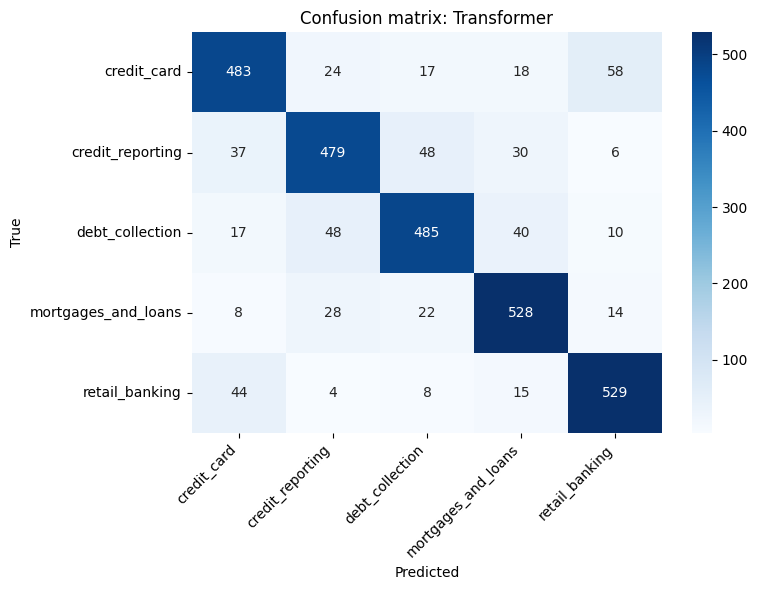

In [19]:
pred_out = trainer.predict(ds_test)
evaluate('Transformer', y_test, pred_out.predictions.argmax(axis=-1))

## 11. Compare the four models

,Accuracy,Precision,Recall,F1-score
Transformer,0.8347,0.8344,0.8347,0.8343
GRU,0.8160,0.8208,0.8160,0.8165
LSTM,0.8127,0.8124,0.8127,0.8121
SimpleRNN,0.7883,0.7885,0.7883,0.7879


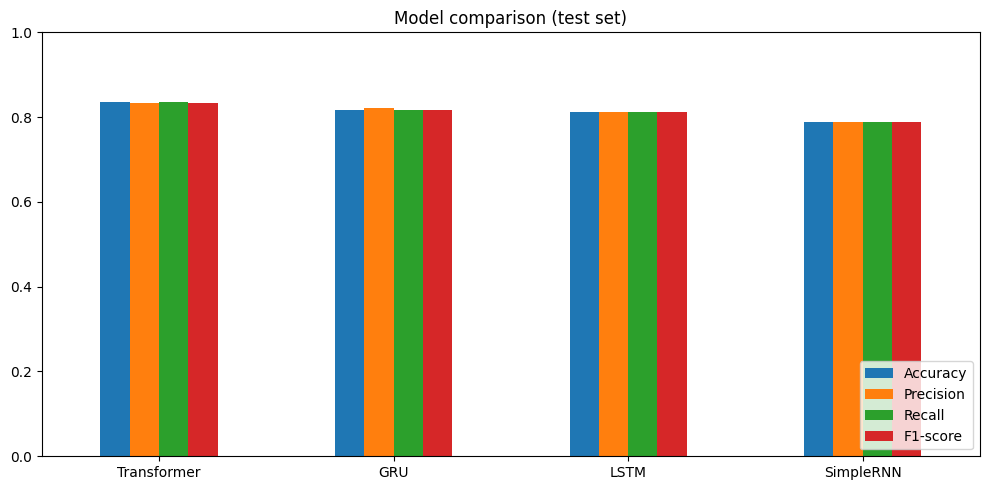

Best model: Transformer


In [20]:
comparison = pd.DataFrame(results).T.round(4).sort_values('F1-score', ascending=False)
display(comparison)

comparison.plot(kind='bar', figsize=(10, 5), ylim=(0, 1))
plt.title('Model comparison (test set)'); plt.xticks(rotation=0); plt.legend(loc='lower right')
plt.tight_layout(); plt.show()

best_name = comparison.index[0]
print('Best model:', best_name)

## 12. Classify new complaints with the best model

In [21]:
def predict_complaint(text):
    """Returns (predicted_category, confidence, {category: probability}) using the best model."""
    if best_name == 'Transformer':
        enc = hf_tok(light_clean(text), truncation=True, max_length=TRANSFORMER_MAXLEN, return_tensors='pt').to(hf_model.device)
        hf_model.eval()
        with torch.no_grad():
            probs = torch.softmax(hf_model(**enc).logits, dim=-1)[0].cpu().numpy()
    else:
        probs = keras_models[best_name].predict(encode([clean_text(text)]), verbose=0)[0]
    idx = int(np.argmax(probs))
    return id2label[idx], float(probs[idx]), {id2label[i]: float(p) for i, p in enumerate(probs)}

samples = [
    "I found accounts on my credit report that I never opened and the bureau refuses to remove them.",
    "The debt collector keeps calling me at work and threatening to sue me for a debt I already paid.",
    "My mortgage servicer misapplied my payments and added late fees even though I paid on time.",
    "A charge of $300 appeared on my card that I did not authorize and the bank denied my dispute.",
]
for s in samples:
    label, conf, _ = predict_complaint(s)
    print(f'{label}  ({conf:.1%})  <-  {s[:80]}...')

credit_reporting  (76.6%)  <-  I found accounts on my credit report that I never opened and the bureau refuses ...
debt_collection  (96.6%)  <-  The debt collector keeps calling me at work and threatening to sue me for a debt...
mortgages_and_loans  (94.5%)  <-  My mortgage servicer misapplied my payments and added late fees even though I pa...
credit_card  (85.7%)  <-  A charge of $300 appeared on my card that I did not authorize and the bank denie...


## 13. Save artifacts for deployment

In [22]:
# Everything the Gradio app needs
with open(f'{ARTIFACTS_DIR}/label_map.json', 'w') as f:
    json.dump({'classes': classes, 'id2label': {str(k): v for k, v in id2label.items()}}, f)
comparison.to_csv(f'{ARTIFACTS_DIR}/model_comparison.csv')
with open(f'{ARTIFACTS_DIR}/best_model.txt', 'w') as f:
    f.write(best_name)
with open(f'{ARTIFACTS_DIR}/config.json', 'w') as f:
    json.dump({'MAX_LEN': MAX_LEN, 'MAX_VOCAB': MAX_VOCAB, 'TRANSFORMER_NAME': TRANSFORMER_NAME,
               'TRANSFORMER_MAXLEN': TRANSFORMER_MAXLEN, 'USE_LEMMATIZER': USE_LEMMATIZER}, f)

# RNN-side artifacts (tokenizer + all three Keras models)
tokenizer.save(f'{ARTIFACTS_DIR}/tokenizer.json')
for name, m in keras_models.items():
    m.save(f'{ARTIFACTS_DIR}/{name.lower()}_model.keras')

# Transformer artifacts
trainer.save_model(f'{ARTIFACTS_DIR}/transformer_model')
hf_tok.save_pretrained(f'{ARTIFACTS_DIR}/transformer_model')

print('Saved:', os.listdir(ARTIFACTS_DIR))
print('Best model:', best_name)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved: ['config.json', 'lstm_model.keras', 'gru_model.keras', 'label_map.json', 'best_model.txt', 'model_comparison.csv', 'tokenizer.json', 'simplernn_model.keras', 'transformer_model']
Best model: Transformer


In [23]:
# Optional: zip and download (Colab)
!zip -rq artifacts.zip artifacts
try:
    from google.colab import files
    files.download('artifacts.zip')
except Exception as e:
    print('Download manually from the file browser:', e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Deployment (Gradio)
_Left for you._ Load the files from `artifacts/` (`best_model.txt` tells you which model won, `label_map.json` maps ids to categories, `tokenizer.json` + `config.json` for the RNN models, `transformer_model/` for the transformer) and wrap `predict_complaint` in a `gr.Interface` returning the predicted category and confidence.

In [24]:
!pip install -q gradio

In [25]:
import gradio as gr

EXAMPLES = [
    "I found accounts on my credit report that I never opened and the bureau refuses to remove them.",
    "The debt collector keeps calling me at work and threatening to sue me for a debt I already paid.",
    "My mortgage servicer misapplied my payments and added late fees even though I paid on time.",
    "A charge of $300 appeared on my card that I did not authorize and the bank denied my dispute.",
]

def classify(text):
    if not text or not text.strip():
        return "Please enter a complaint.", "", {}
    label, conf, probs = predict_complaint(text)
    return label, f"{conf:.1%}", probs

demo = gr.Interface(
    fn=classify,
    inputs=gr.Textbox(lines=8, label="Complaint narrative", placeholder="Paste or type the customer's complaint here..."),
    outputs=[
        gr.Textbox(label="Predicted category"),
        gr.Textbox(label="Confidence score"),
        gr.Label(num_top_classes=NUM_CLASSES, label="Probability per category"),
    ],
    examples=EXAMPLES,
    title="Consumer Complaint Classifier",
    description=f"Predicts the complaint category from the complaint text. Model in use: {best_name}.",
    flagging_mode="never",
)
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://070cf7629f10f15969.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
